## Forecasting experiment

Which approach best forecasts daily appointment volume per clinic

- **What is our target?** The number of booked appointments per clinic per day, counting only `Completed` and `No-Show` (appointments that actually took a slot). Cancelled and rescheduled appointments never used a slot, so they don't count as demand.

### Data Preparation

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_percentage_error, root_mean_squared_error, mean_absolute_error

warnings.filterwarnings("ignore")

df = pd.read_csv("../data/AppointmentRecords.csv", parse_dates=["AppointmentDateTime"])
df = df.drop_duplicates(subset=[c for c in df.columns if c != "AppointmentID"])

In [2]:
df["AppointmentType"].value_counts()

AppointmentType
Follow-Up      57859
Telehealth     30117
New Patient    21583
Urgent         19793
Name: count, dtype: int64

In [3]:
df["BookingChannel"].value_counts()

BookingChannel
Online      57061
Phone       39272
Referral    19394
Walk-In     13625
Name: count, dtype: int64

In [4]:
df["SeasonFlag"].value_counts()

SeasonFlag
Standard          64014
Flu Season        34614
Allergy Season    30724
Name: count, dtype: int64

In [5]:
df["IsHoliday"].value_counts()

IsHoliday
False    128413
True        939
Name: count, dtype: int64

In [6]:
df.columns

Index(['AppointmentID', 'ClinicID', 'ClinicName', 'ClinicType', 'PatientID',
       'ProviderID', 'AppointmentDateTime', 'AppointmentType', 'Status',
       'BookingChannel', 'BookingLeadTimeDays', 'IsHoliday', 'HolidayName',
       'SeasonFlag', 'ChronicConditionFlag'],
      dtype='str')

In [7]:
df['Date'] = df["AppointmentDateTime"].dt.normalize()
df.groupby("Date")["AppointmentID"].count()

Date
2024-01-01     31
2024-01-02    221
2024-01-03    167
2024-01-04    171
2024-01-05    103
             ... 
2025-12-27    153
2025-12-28     25
2025-12-29    332
2025-12-30    325
2025-12-31     51
Name: AppointmentID, Length: 731, dtype: int64

In [8]:
booked = df[df['Status'].isin(["Completed", "No-Show"])]
booked['Status'].value_counts()

Status
Completed    109039
No-Show       11367
Name: count, dtype: int64

In [9]:
df['ClinicName'].nunique()

4

In [10]:
series = []
for clinic, group in booked.groupby("ClinicName"):
    s = group.groupby("Date").size()
    s = s.reindex(pd.date_range(s.index.min(), df["Date"].max()), fill_value=0)
    series.append(pd.DataFrame({
        "Clinic": clinic.replace("Nexora Care - ", ""),
        "Date": s.index,
        "y": s.values
    }))
daily_data = pd.concat(series, ignore_index=True)
daily_data.groupby("Clinic")["y"].describe().round()

,count,mean,std,min,25%,50%,75%,max
Clinic,,,,,,,,
Downtown Express,731.0,32.0,11.0,0.0,24.0,33.0,40.0,78.0
Hillcrest,551.0,49.0,30.0,0.0,19.0,59.0,73.0,117.0
Lakeside,731.0,58.0,32.0,0.0,40.0,66.0,80.0,134.0
Riverside,731.0,37.0,23.0,0.0,16.0,44.0,55.0,91.0


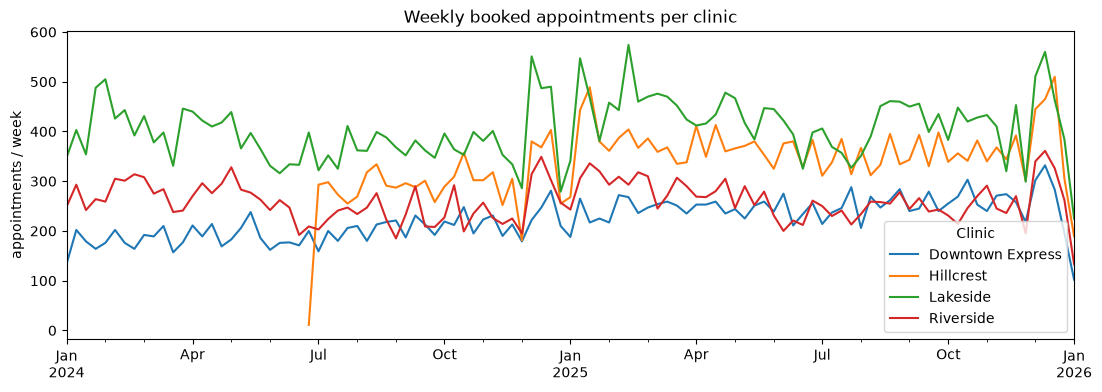

In [11]:
# make a plot of the weekly representation of our data
weekly = daily_data.set_index("Date").groupby("Clinic")["y"].resample("W-SUN").sum().unstack(0)
weekly.plot(figsize=(13, 4), title="Weekly booked appointments per clinic")
plt.xlabel(""); plt.ylabel("appointments / week")
plt.show()

In [12]:
daily_data

,Clinic,Date,y
0,Downtown Express,2024-01-01,5
1,Downtown Express,2024-01-02,33
2,Downtown Express,2024-01-03,21
3,Downtown Express,2024-01-04,28
4,Downtown Express,2024-01-05,21
...,...,...,...
2739,Riverside,2025-12-27,20
2740,Riverside,2025-12-28,0
2741,Riverside,2025-12-29,69
2742,Riverside,2025-12-30,55


In [13]:
exogenous_data = df.groupby("Date")[["IsHoliday", "SeasonFlag"]].first()

train_data = daily_data.merge(exogenous_data, left_on="Date", how="left", right_index=True)
train_data

,Clinic,Date,y,IsHoliday,SeasonFlag
0,Downtown Express,2024-01-01,5,True,Flu Season
1,Downtown Express,2024-01-02,33,False,Flu Season
2,Downtown Express,2024-01-03,21,False,Flu Season
3,Downtown Express,2024-01-04,28,False,Flu Season
4,Downtown Express,2024-01-05,21,False,Flu Season
...,...,...,...,...,...
2739,Riverside,2025-12-27,20,False,Flu Season
2740,Riverside,2025-12-28,0,False,Flu Season
2741,Riverside,2025-12-29,69,False,Flu Season
2742,Riverside,2025-12-30,55,False,Flu Season


In [14]:
train_data['IsHoliday'] = train_data["IsHoliday"].astype(int)

In [15]:
train_data['dow'] = train_data['Date'].dt.day_of_week # 0 = Monday ...... Sunday = 6

In [16]:
def encode(data):
    return pd.get_dummies(
        data,
        columns=['Clinic', 'SeasonFlag', 'dow'],
        dtype=float
    )

In [17]:
# day of the week, year, month(encode), day
encode(train_data)  # preview of what the ML models see

,Date,y,IsHoliday,Clinic_Downtown Express,Clinic_Hillcrest,Clinic_Lakeside,Clinic_Riverside,SeasonFlag_Allergy Season,SeasonFlag_Flu Season,SeasonFlag_Standard,dow_0,dow_1,dow_2,dow_3,dow_4,dow_5,dow_6
0,2024-01-01,5,1,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2024-01-02,33,0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
2,2024-01-03,21,0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
3,2024-01-04,28,0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
4,2024-01-05,21,0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2739,2025-12-27,20,0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2740,2025-12-28,0,0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2741,2025-12-29,69,0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
2742,2025-12-30,55,0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


## Model Experimentation

### Temporal/time splitting: Is the splitting based on Date. train_test-split

In [18]:
from sklearn.model_selection import train_test_split

# Sort by date (then clinic) so that "last rows" = "latest dates". Keep Date: we need it to read the results
train_data_sorted = train_data.sort_values(["Date", "Clinic"]).reset_index(drop=True)
test_weeks = 13
test_rows = test_weeks * 7 * train_data_sorted["Clinic"].nunique()

train, test = train_test_split(train_data_sorted, test_size=test_rows, shuffle=False)

print(train.shape)
print(test.shape)

(2380, 6)
(364, 6)


### Evaluation helpers
- `evaluate(model)` trains on `train`, forecasts `test`, sets days a clinic is always closed (e.g. Sunday) to 0 and removes negative forecasts.
- `score(...)` computes MAPE, RMSE and MAE on open days (MAPE can't divide by an actual of 0).
- `results` collects every model's predictions so they can be compared at the end.

In [19]:
def evaluate(model):
    """Train on `train`, forecast `test`, return actual vs predicted for every test day."""
    pred = pd.Series(np.asarray(model(train, test), dtype=float), index=test.index)

    # (Clinic, weekday) pairs with a median of 0 in training are closed days -> forecast 0
    closed = train.groupby(["Clinic", "dow"])["y"].median().loc[lambda s: s == 0].index
    pred[pd.MultiIndex.from_frame(test[["Clinic", "dow"]]).isin(closed)] = 0
    return test[["Clinic", "Date", "y", "IsHoliday"]].assign(pred=pred.clip(lower=0))

def score(results_df):
    d = results_df[results_df["y"] > 0]
    return pd.Series({
        "RMSE": root_mean_squared_error(d["y"], d["pred"]),
        "MAE": mean_absolute_error(d["y"], d["pred"]),
    })

results = {}  # model name -> test predictions

## SARIMA / SARIMAX
One model per clinic, learning from that clinic's own past counts with a **weekly** repeating pattern (`s = `7).
- **SARIMA:** past counts only.
- **SARIMAX:** past counts **+** `IsHoliday` and `SeasonFlag` (the X = extra information).

Order `(1,0,1)(0,1,1,7)` is a standard starting point for daily data with a weekly cycle.


"Start from the same day last week (D=1, s=7), adjust for last week's error on that weekday (Q=1), then fine-tune using yesterday's level (p=1) and yesterday's error (q=1)."

(AR I MA)(AR I MA s)
(p d q)(P D Q s)
(1 1 1)(0 1 1 7)

autoregressive = use yesterdays value
differencing = how different todays is from yesterdays/How different todays value is from same day 7 days ago
error = model correcting itself from error yesterday/model correcting itself from the erros 1 week from today
s (seasonality) = 7 days interval

In [20]:
EXOG = ["IsHoliday", "SeasonFlag_Flu Season", "SeasonFlag_Allergy Season", "SeasonFlag_Standard"]

def sarimax_forecast(use_exog):
    def fn(train, test):
        pred = pd.Series(index=test.index, dtype=float)
        for clinic, clinic_test in test.groupby("Clinic"):
            clinic_train = train[train["Clinic"] == clinic]
            X_train = encode(clinic_train).reindex(columns=EXOG, fill_value=0).values if use_exog else None
            X_test = encode(clinic_test).reindex(columns=EXOG, fill_value=0).values if use_exog else None
            fit = SARIMAX(clinic_train["y"].values, exog=X_train, order=(1, 0, 1), seasonal_order=(0, 1, 1, 7)).fit(disp=False)
            pred[clinic_test.index] = fit.forecast(len(clinic_test), exog=X_test)
        return pred
    return fn

results["SARIMA"] = evaluate(sarimax_forecast(use_exog=False))
results["SARIMAX"] = evaluate(sarimax_forecast(use_exog=True))
pd.DataFrame({m: score(p) for m, p in results.items()}).T.round(2)

,RMSE,MAE
SARIMA,18.84,12.68
SARIMAX,9.83,7.34


## Machine learning
One model for all clinics together, with clinic as an input. The inputs are just clinic, day of week, `IsHoliday` and `SeasonFlag`.

| Model | Why try it |
|---|---|
| Linear Regression | Simplest benchmark: adds up a fixed effect per input |
| Random Forest | Many decision trees averaged; captures combinations (e.g. *holiday at Lakeside*) |
| HistGradientBoosting | Trees built one after another, each fixing the last one's errors |

In [21]:
def ml_forecast(model):
    def fn(train, test):
        # encode() keeps every column, so drop the answer (y) and the raw Date before training
        X_train = encode(train).drop(columns=["Date", "y"])
        X_test = encode(test).drop(columns=["Date", "y"]).reindex(columns=X_train.columns, fill_value=0)
        return model.fit(X_train, train["y"]).predict(X_test)
    return fn

ML_MODELS = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=3, n_jobs=-1, random_state=42),
    "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, random_state=42),
}
for name, model in ML_MODELS.items():
    results[name] = evaluate(ml_forecast(model))

pd.DataFrame({m: score(p) for m, p in results.items()}).T.round(2)

,RMSE,MAE
SARIMA,18.84,12.68
SARIMAX,9.83,7.34
Linear Regression,14.65,10.95
Random Forest,11.37,8.54
HistGradientBoosting,11.39,8.56


In [22]:
import joblib
from pathlib import Path

# Save the Random Forest (already fitted on `train` in the loop above)
model_dir = Path("../models")
model_dir.mkdir(parents=True, exist_ok=True)

rf_model = ML_MODELS["Random Forest"]
feature_columns = list(encode(train).drop(columns=["Date", "y"]).columns)

joblib.dump(
    {"model": rf_model, "feature_columns": feature_columns},
    model_dir / "random_forest.joblib",
)
print(f"Saved to {(model_dir / 'random_forest.joblib').resolve()}")

Saved to C:\Users\HomePC\Downloads\september-cohort\appointment-volume-forecasting\nexora-forecasting\models\random_forest.joblib
